# Experiment 8: Multi-Agent Task Allocation and Coordination

**Aim:** To implement a simple multi-agent task allocation system using Partial Global Planning (PGP) and Contract Net Protocol (CNP).

## Exercise 1: Agent Setup
Create a Python-based system with 1 Manager Agent and at least 3 Delivery Agents.  
Add at least 6 delivery tasks with different costs/times for each agent.

In [1]:
# Exercise 1: Agent Setup

TASKS = {
    'T1': 'Deliver to Location A',
    'T2': 'Deliver to Location B',
    'T3': 'Deliver to Location C',
    'T4': 'Deliver to Location D',
    'T5': 'Deliver to Location E',
    'T6': 'Deliver to Location F',
}

COST_TABLE = {
    'Agent1': {'T1': 10, 'T2': 20, 'T3': 15, 'T4': 25, 'T5': 30, 'T6': 18},
    'Agent2': {'T1': 12, 'T2': 18, 'T3': 22, 'T4': 20, 'T5': 28, 'T6': 14},
    'Agent3': {'T1': 14, 'T2': 16, 'T3': 10, 'T4': 30, 'T5': 22, 'T6': 20},
    'Agent4': {'T1': 16, 'T2': 24, 'T3': 18, 'T4': 15, 'T5': 20, 'T6': 12},
}

AGENTS = list(COST_TABLE.keys())
MANAGER = 'Manager'

print(f"Manager Agent  : {MANAGER}")
print(f"Delivery Agents: {AGENTS}")
print(f"Tasks          : {list(TASKS.keys())}")
print()
print("Cost Table (minutes):")
header = f"{'Agent':<10}" + "".join(f"{t:>6}" for t in TASKS)
print(header)
print("-" * len(header))
for agent, costs in COST_TABLE.items():
    row = f"{agent:<10}" + "".join(f"{costs[t]:>6}" for t in TASKS)
    print(row)


Manager Agent  : Manager
Delivery Agents: ['Agent1', 'Agent2', 'Agent3', 'Agent4']
Tasks          : ['T1', 'T2', 'T3', 'T4', 'T5', 'T6']

Cost Table (minutes):
Agent         T1    T2    T3    T4    T5    T6
----------------------------------------------
Agent1        10    20    15    25    30    18
Agent2        12    18    22    20    28    14
Agent3        14    16    10    30    22    20
Agent4        16    24    18    15    20    12


## Exercise 2: PGP Coordination
Create local plans for agents, introduce a resource conflict, detect it, and resolve it.

In [2]:
# Exercise 2: PGP Coordination

# Local plan: agent -> list of (task, start_time, location)
local_plans = {
    'Agent1': [('T1', 0,  'LocationA'), ('T3', 20, 'LocationC')],
    'Agent2': [('T2', 0,  'LocationB'), ('T3', 20, 'LocationC')],  # conflict with Agent1
    'Agent3': [('T5', 0,  'LocationE'), ('T6', 25, 'LocationF')],
    'Agent4': [('T4', 0,  'LocationD')],
}

def detect_conflicts(plans):
    """Detect tasks at the same (location, start_time) by different agents."""
    schedule = {}
    conflicts = []
    for agent, plan in plans.items():
        for task, start, location in plan:
            key = (location, start)
            if key in schedule:
                conflicts.append((key, schedule[key], agent, task))
            else:
                schedule[key] = agent
    return conflicts

conflicts = detect_conflicts(local_plans)
print("=== PGP: Local Plans ===")
for agent, plan in local_plans.items():
    print(f"  {agent}: {plan}")
print()

if conflicts:
    print("=== Conflicts Detected ===")
    for (loc, t), a1, a2, task in conflicts:
        print(f"  Conflict at {loc} @ t={t} between {a1} and {a2} (task {task})")
else:
    print("No conflicts detected.")

print()
print("=== Resolving Conflicts ===")
for (loc, t), a1, a2, task in conflicts:
    plan = local_plans[a2]
    for i, (tk, st, lc) in enumerate(plan):
        if tk == task and st == t and lc == loc:
            new_start = st + 10
            plan[i] = (tk, new_start, lc)
            print(f"  {a2}'s task {task} rescheduled: t={t} -> t={new_start}")

print()
print("=== Updated Plans After PGP Resolution ===")
for agent, plan in local_plans.items():
    print(f"  {agent}: {plan}")

remaining = detect_conflicts(local_plans)
print()
print("Conflicts after resolution:", remaining if remaining else "None")


=== PGP: Local Plans ===
  Agent1: [('T1', 0, 'LocationA'), ('T3', 20, 'LocationC')]
  Agent2: [('T2', 0, 'LocationB'), ('T3', 20, 'LocationC')]
  Agent3: [('T5', 0, 'LocationE'), ('T6', 25, 'LocationF')]
  Agent4: [('T4', 0, 'LocationD')]

=== Conflicts Detected ===
  Conflict at LocationC @ t=20 between Agent1 and Agent2 (task T3)

=== Resolving Conflicts ===
  Agent2's task T3 rescheduled: t=20 -> t=30

=== Updated Plans After PGP Resolution ===
  Agent1: [('T1', 0, 'LocationA'), ('T3', 20, 'LocationC')]
  Agent2: [('T2', 0, 'LocationB'), ('T3', 30, 'LocationC')]
  Agent3: [('T5', 0, 'LocationE'), ('T6', 25, 'LocationF')]
  Agent4: [('T4', 0, 'LocationD')]

Conflicts after resolution: None


## Exercise 3: CNP Task Allocation
Implement CNP: Announcement -> Bidding -> Bid Comparison -> Agent Selection -> Task Assignment.

In [3]:
# Exercise 3: CNP Task Allocation (single task demonstration)

def cnp_single_task(task_id, cost_table, agents):
    print(f"\n--- CNP for Task: {task_id} ---")
    # Step 1: Task Announcement
    print(f"[Manager] Announcing task '{task_id}' to all agents...")
    # Step 2: Bidding
    bids = {}
    for agent in agents:
        bid = cost_table[agent][task_id]
        bids[agent] = bid
        print(f"  [{agent}] submits bid: {bid} min")
    # Step 3: Bid Comparison
    print(f"[Manager] Comparing bids: {bids}")
    # Step 4: Agent Selection (lowest cost wins)
    selected = min(bids, key=bids.get)
    print(f"[Manager] Selected agent: {selected} with cost {bids[selected]} min")
    # Step 5: Task Assignment
    print(f"[Manager] Assigning '{task_id}' to {selected}")
    return selected, bids[selected]

demo_agent, demo_cost = cnp_single_task('T1', COST_TABLE, AGENTS)
print(f"\nResult: Task T1 assigned to {demo_agent} at cost {demo_cost} min")



--- CNP for Task: T1 ---
[Manager] Announcing task 'T1' to all agents...
  [Agent1] submits bid: 10 min
  [Agent2] submits bid: 12 min
  [Agent3] submits bid: 14 min
  [Agent4] submits bid: 16 min
[Manager] Comparing bids: {'Agent1': 10, 'Agent2': 12, 'Agent3': 14, 'Agent4': 16}
[Manager] Selected agent: Agent1 with cost 10 min
[Manager] Assigning 'T1' to Agent1

Result: Task T1 assigned to Agent1 at cost 10 min


## Exercise 4: Multiple Task Allocation
Allocate all tasks using CNP. Display final allocation table and total cost.

In [4]:
# Exercise 4: Multiple Task Allocation

def allocate_all_tasks(tasks, cost_table, agents):
    """Allocate all tasks via CNP (greedy: lowest bid per task)."""
    allocation = {}
    for task_id in tasks:
        bids = {agent: cost_table[agent][task_id] for agent in agents}
        best_agent = min(bids, key=bids.get)
        allocation[task_id] = (best_agent, bids[best_agent])
    return allocation

allocation = allocate_all_tasks(TASKS, COST_TABLE, AGENTS)

print("=" * 45)
print(f"{'Task':<6} | {'Selected Agent':<14} | {'Cost/Time (min)':<15}")
print("-" * 45)
total_cost = 0
for task, (agent, cost) in allocation.items():
    print(f"{task:<6} | {agent:<14} | {cost:<15}")
    total_cost += cost
print("=" * 45)
print(f"{'TOTAL':<6} | {'':<14} | {total_cost:<15}")
print("=" * 45)


Task   | Selected Agent | Cost/Time (min)
---------------------------------------------
T1     | Agent1         | 10             
T2     | Agent3         | 16             
T3     | Agent3         | 10             
T4     | Agent4         | 15             
T5     | Agent4         | 20             
T6     | Agent4         | 12             
TOTAL  |                | 83             


## Exercise 5: Modification & Visualization
Change costs, re-run allocation, compare results, and plot Agent vs Total Assigned Cost.

Allocation Run 1 (Original Costs):
  Task   Agent        Cost
  T1     Agent1         10
  T2     Agent3         16
  T3     Agent3         10
  T4     Agent4         15
  T5     Agent4         20
  T6     Agent4         12
  Total: 83 min

Allocation Run 2 (Modified Costs):
  Task   Agent        Cost
  T1     Agent2         12
  T2     Agent3          8
  T3     Agent3         10
  T4     Agent4         15
  T5     Agent4         20
  T6     Agent4          5
  Total: 70 min


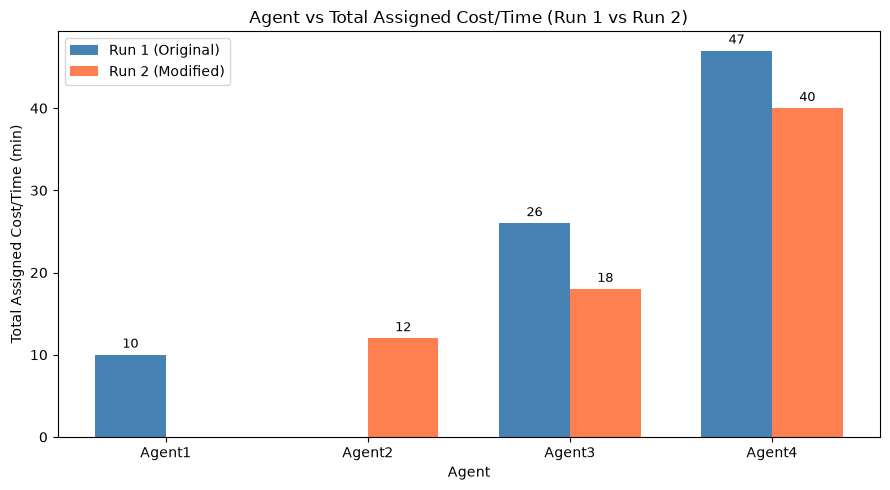

In [5]:
# Exercise 5: Modification & Visualization
import matplotlib.pyplot as plt
import copy

def agent_total_cost(allocation):
    """Compute total cost per agent from an allocation."""
    totals = {}
    for task, (agent, cost) in allocation.items():
        totals[agent] = totals.get(agent, 0) + cost
    return totals

# Run 1: Original costs
alloc1 = allocate_all_tasks(TASKS, COST_TABLE, AGENTS)
totals1 = agent_total_cost(alloc1)

# Modify some costs
COST_TABLE_MOD = copy.deepcopy(COST_TABLE)
COST_TABLE_MOD['Agent1']['T1'] = 25   # Agent1 more expensive for T1
COST_TABLE_MOD['Agent1']['T3'] = 30   # Agent1 more expensive for T3
COST_TABLE_MOD['Agent3']['T2'] = 8    # Agent3 cheaper for T2
COST_TABLE_MOD['Agent4']['T6'] = 5    # Agent4 very cheap for T6

# Run 2: Modified costs
alloc2 = allocate_all_tasks(TASKS, COST_TABLE_MOD, AGENTS)
totals2 = agent_total_cost(alloc2)

# Print comparison
print("Allocation Run 1 (Original Costs):")
print(f"  {'Task':<6} {'Agent':<10} {'Cost':>6}")
for t, (a, c) in alloc1.items():
    print(f"  {t:<6} {a:<10} {c:>6}")
print(f"  Total: {sum(c for _, c in alloc1.values())} min\n")

print("Allocation Run 2 (Modified Costs):")
print(f"  {'Task':<6} {'Agent':<10} {'Cost':>6}")
for t, (a, c) in alloc2.items():
    print(f"  {t:<6} {a:<10} {c:>6}")
print(f"  Total: {sum(c for _, c in alloc2.values())} min")

# Plot: Agent vs Total Assigned Cost/Time
all_agents = AGENTS
costs1 = [totals1.get(a, 0) for a in all_agents]
costs2 = [totals2.get(a, 0) for a in all_agents]
x = range(len(all_agents))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
bars1 = ax.bar([i - width/2 for i in x], costs1, width, label='Run 1 (Original)', color='steelblue')
bars2 = ax.bar([i + width/2 for i in x], costs2, width, label='Run 2 (Modified)', color='coral')

ax.set_xlabel('Agent')
ax.set_ylabel('Total Assigned Cost/Time (min)')
ax.set_title('Agent vs Total Assigned Cost/Time (Run 1 vs Run 2)')
ax.set_xticks(list(x))
ax.set_xticklabels(all_agents)
ax.legend()

for bar in bars1:
    if bar.get_height() > 0:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                str(int(bar.get_height())), ha='center', va='bottom', fontsize=9)
for bar in bars2:
    if bar.get_height() > 0:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                str(int(bar.get_height())), ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()
